<a href="https://colab.research.google.com/github/HarikaPonnaganti-coder/Machine-Learning/blob/main/KMeans_Clustering_AP24110010828_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Means Clustering
Name:P.Harika
Reg No: AP24110010828


 Clustering:
Clustering groups data points that have similar patterns. Points in the same group should be more alike than points in other groups. It is an unsupervised learning technique because we do not provide output labels.

 How is Clustering an Unsupervised Learning Problem?
In supervised learning, the model learns from known answers or labels. In clustering, there is no target label. The algorithm examines the features and finds groups by itself.

 Properties of Clusters
- Points in one cluster should be similar based on the selected features.
- Points in different clusters should be less similar.
- The grouping depends on the dataset and clustering method.

 Applications of Clustering
Clustering is used in customer segmentation, grouping similar documents, image segmentation, and exploring patterns in data. For example, a shop can group customers by their purchase patterns.

 Evaluation Metrics
**Inertia:** total squared distance of data points from their assigned centroids. Lower inertia means points are closer to their centroids, but it usually decreases as K increases.

**Dunn Index:** compares separation between clusters with spread inside clusters. Higher is generally better.

**Silhouette Score:** compares a point's similarity to its own cluster with its similarity to other clusters. Values closer to 1 indicate clearer separation, near 0 indicate overlap, and negative values can mean poor assignment.

What is K-Means Clustering?
K-Means is a centroid-based algorithm. We choose K groups, assign each point to the nearest centroid, then move each centroid to the mean of its assigned points. It repeats these steps until the groups stop changing much.

How K-Means Works
1. Choose the number of clusters (K).
2. Select initial centroids.
3. Assign each point to its nearest centroid.
4. Calculate the mean of each group to update its centroid.
5. Repeat assignment and update until the centroids or assignments stop changing.

The graph below shows a small example of this process.

### Simple illustration of K-Means steps
We use six sample points and two initial centroids. The points are assigned to the nearest centroid, and each centroid is moved to the mean of its assigned points.

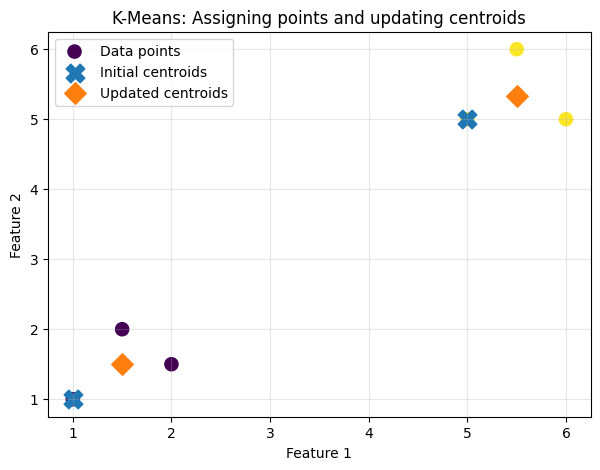

Updated centroids: [[1.5        1.5       ]
 [5.5        5.33333333]]


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Small set of points for illustrating the steps
points = np.array([[1, 1], [1.5, 2], [2, 1.5], [5, 5], [6, 5], [5.5, 6]])
initial_centroids = np.array([[1, 1], [5, 5]])                                    #AP24110010828

# Assign points to the closest initial centroid
distances = np.linalg.norm(points[:, None, :] - initial_centroids[None, :, :], axis=2)
labels = distances.argmin(axis=1)

# Update centroids using the mean of assigned points
updated_centroids = np.array([points[labels == i].mean(axis=0) for i in range(2)])

plt.figure(figsize=(7, 5))
plt.scatter(points[:, 0], points[:, 1], c=labels, s=90, label='Data points')
plt.scatter(initial_centroids[:, 0], initial_centroids[:, 1], marker='X', s=180, label='Initial centroids')
plt.scatter(updated_centroids[:, 0], updated_centroids[:, 1], marker='D', s=120, label='Updated centroids')
plt.title('K-Means: Assigning points and updating centroids')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')             #AP24110010828
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
print('Updated centroids:', updated_centroids)

Implementing K-Means from Scratch
This code builds a simple K-Means function. It calculates distances, assigns labels, updates centroids, and repeats. A graph shows the final groups and their centroids.

Cluster labels: [0 0 0 1 1 1]
Centroids: [[1.5        1.5       ]
 [5.5        5.33333333]]


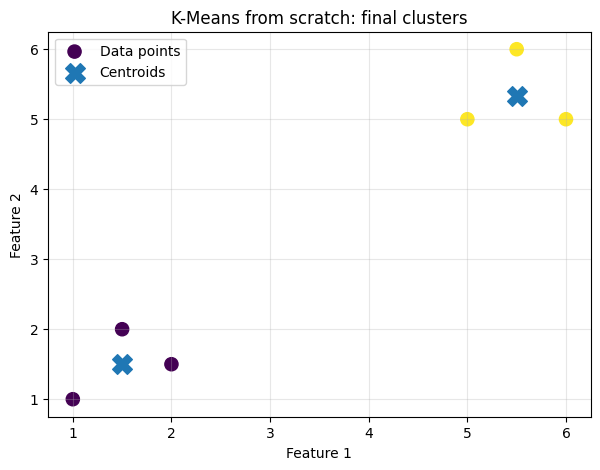

In [ ]:

import numpy as np

def simple_kmeans(data, k, max_iter=100, random_state=42):
    rng = np.random.default_rng(random_state)
    centroids = data[rng.choice(len(data), size=k, replace=False)].astype(float)    #AP24110010828
    for _ in range(max_iter):
        distances = np.linalg.norm(data[:, None, :] - centroids[None, :, :], axis=2)
        labels = distances.argmin(axis=1)
        updated = np.array([
            data[labels == i].mean(axis=0) if np.any(labels == i) else centroids[i]
            for i in range(k)
        ])
        if np.allclose(centroids, updated):
            break
        centroids = updated
    return labels, centroids

labels, centers = simple_kmeans(points, k=2)
print('Cluster labels:', labels)
print('Centroids:', centers)
                                                 #AP24110010828
# Plot the final groups and centroids
plt.figure(figsize=(7, 5))
plt.scatter(points[:, 0], points[:, 1], c=labels, s=90, label='Data points')
plt.scatter(centers[:, 0], centers[:, 1], marker='X', s=200, label='Centroids')
plt.title('K-Means from scratch: final clusters')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

 Challenges with K-Means
K-Means can give different results when the starting centroids change. It can be affected by outliers and works best for compact groups. It may not work well when clusters have unusual shapes or very different sizes.

### Solution mentioned in the article
K-Means++ chooses initial centroids more carefully by considering distances, which can help avoid poor starting positions.

 K-Means++ Initialization
K-Means++ spreads the starting centroids out using a distance-based selection process. Scikit-learn supports it with `init='k-means++'`.

In [ ]:
#AP24110010828
from sklearn.cluster import KMeans

km_plus = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
km_plus.fit(points)
print("Centroids:", km_plus.cluster_centers_)
print("Labels:", km_plus.labels_)  #AP24110010828

Centroids: [[1.75       1.75      ]
 [5.5        5.33333333]
 [1.         1.        ]]
Labels: [2 0 0 1 1 1]


 Choosing the Right Number of Clusters (Elbow Method)
We run K-Means for different K values and record inertia. The curve usually drops quickly at first and then starts to flatten. The point where the drop slows is called the elbow and can be a possible K. It is a guide, not an exact rule.

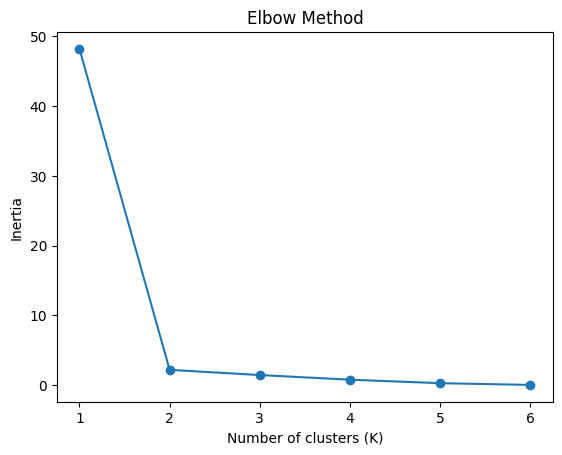

In [ ]:

inertia_values = []
# The dataset has only 6 samples, so K can go from 1 up to 6
k_values = range(1, len(points) + 1)

for k in k_values:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    model.fit(points)
    inertia_values.append(model.inertia_)
                                              #AP24110010828
plt.plot(k_values, inertia_values, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

   Implementing K-Means on the Wholesale Customers Dataset
The article uses the Wholesale Customers dataset, which has spending information across product categories. We load the data, check its statistics, standardize the columns, and apply K-Means.

In [ ]:

import pandas as pd
import numpy as np                            #AP24110010828
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load the Wholesale Customers data from UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
data = pd.read_csv(url)
data.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


### Dataset statistics

In [ ]:

data.describe()    #AP24110010828

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


### Standardize the data
The columns have different ranges. StandardScaler makes their scales comparable (approximately mean 0 and standard deviation 1). This is important because K-Means uses distances, so large-valued features could otherwise dominate.

In [ ]:

scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)      #AP24110010828

pd.DataFrame(data_scaled, columns=data.columns).describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,4.400000e+02,4.400000e+02,4.400000e+02,440.000000,4.400000e+02,4.400000e+02,4.400000e+02,4.400000e+02
mean,1.614870e-17,3.552714e-16,-3.431598e-17,0.000000,-4.037175e-17,3.633457e-17,2.422305e-17,-8.074349e-18
std,1.001138e+00,1.001138e+00,1.001138e+00,1.001138,1.001138e+00,1.001138e+00,1.001138e+00,1.001138e+00
min,-6.902971e-01,-1.995342e+00,-9.496831e-01,-0.778795,-8.373344e-01,-6.283430e-01,-6.044165e-01,-5.402644e-01
25%,-6.902971e-01,-7.023369e-01,-7.023339e-01,-0.578306,-6.108364e-01,-4.804306e-01,-5.511349e-01,-3.964005e-01
50%,-6.902971e-01,5.906683e-01,-2.767602e-01,-0.294258,-3.366684e-01,-3.188045e-01,-4.336004e-01,-1.985766e-01
75%,1.448652e+00,5.906683e-01,3.905226e-01,0.189092,2.849105e-01,9.946441e-02,2.184822e-01,1.048598e-01
max,1.448652e+00,5.906683e-01,7.927738e+00,9.183650,8.936528e+00,1.191900e+01,7.967672e+00,1.647845e+01


### Fit K-Means with K-Means++ initialization
We fit K-Means on the standardized dataset with two clusters for this example and print inertia, which represents the within-cluster squared distance.

In [ ]:

kmeans = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=42)  #AP24110010828
kmeans.fit(data_scaled)

print("Inertia:", kmeans.inertia_)

Inertia: 2599.387384912305


### Elbow curve for choosing K
We calculate inertia for different cluster counts and plot it. We look for the point after which the decrease becomes smaller.

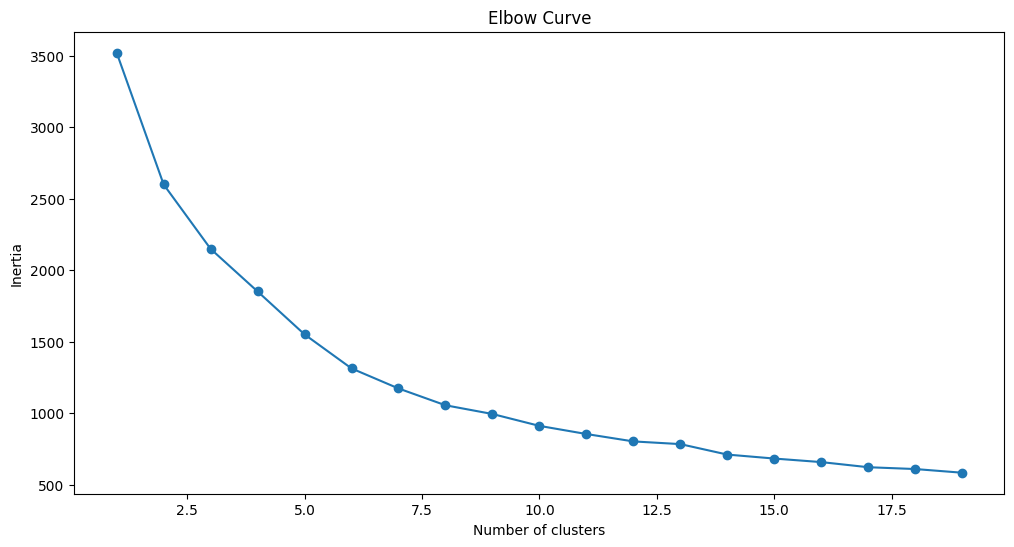

In [ ]:

SSE = []
cluster_range = range(1, 20)

for cluster in cluster_range:
    model = KMeans(n_clusters=cluster, init="k-means++", n_init=10, random_state=42)
    model.fit(data_scaled)
    SSE.append(model.inertia_)  #AP24110010828

frame = pd.DataFrame({"Cluster": list(cluster_range), "SSE": SSE})
plt.figure(figsize=(12, 6))
plt.plot(frame["Cluster"], frame["SSE"], marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Curve")
plt.show()

### Fit the final model and view cluster counts
We fit the example model with five clusters and count how many records are assigned to each. Cluster numbers are just group labels, not rankings.

In [ ]:

# Using 5 clusters, as a choice within the elbow region discussed in the article
final_model = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=42)
final_model.fit(data_scaled)
pred = final_model.predict(data_scaled)
                                           #AP24110010828
cluster_frame = pd.DataFrame(data_scaled, columns=data.columns)
cluster_frame["cluster"] = pred
cluster_frame["cluster"].value_counts()

,count
cluster,
3,207
1,126
2,91
4,10
0,6


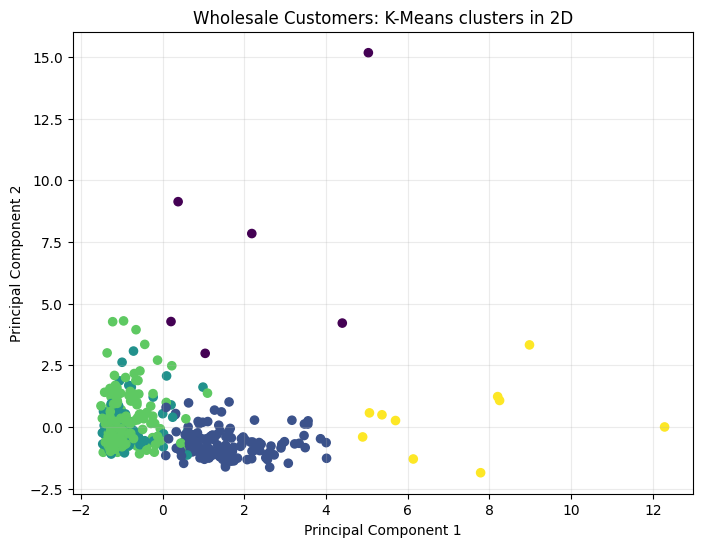

PCA is used only to display the data in two dimensions.


In [ ]:

from sklearn.decomposition import PCA

# PCA reduces the standardized features to two dimensions for plotting
pca = PCA(n_components=2)
data_2d = pca.fit_transform(data_scaled)

plt.figure(figsize=(8, 6))       #AP24110010828
plt.scatter(data_2d[:, 0], data_2d[:, 1], c=pred, s=35)
plt.title('Wholesale Customers: K-Means clusters in 2D')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, alpha=0.25)
plt.show()
print('PCA is used only to display the data in two dimensions.')

## Conclusion
In this notebook, I learned how clustering groups data without target labels. I tried the K-Means steps, a small implementation, K-Means++ initialization, the Elbow Method, and K-Means on the Wholesale Customers dataset.